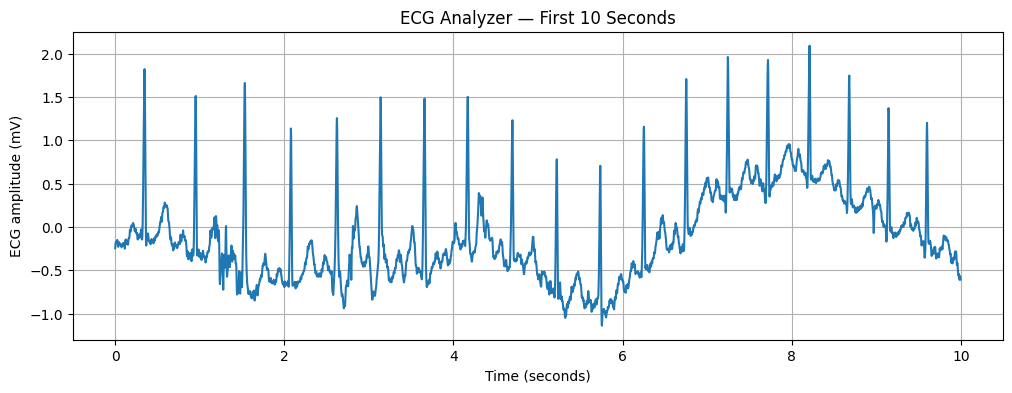

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.datasets import electrocardiogram

ecg = electrocardiogram()

sampling_rate = 360
seconds_to_show = 10
number_of_samples = seconds_to_show * sampling_rate

ecg_segment = ecg[:number_of_samples]
time = np.arange(number_of_samples) / sampling_rate

plt.figure(figsize=(12, 4))
plt.plot(time, ecg_segment)

plt.xlabel("Time (seconds)")
plt.ylabel("ECG amplitude (mV)")
plt.title("ECG Analyzer — First 10 Seconds")
plt.grid(True)
plt.show()

In [17]:
print("First 10 ECG values:")
print(ecg[:10])

print("Total number of samples:")
print(len(ecg))

First 10 ECG values:
[-0.245 -0.215 -0.185 -0.175 -0.17  -0.17  -0.185 -0.17  -0.16  -0.15 ]
Total number of samples:
108000


In [18]:
print("Minimum amplitude:", np.min(ecg_segment))
print("Maximum amplitude:", np.max(ecg_segment))
print("Average amplitude:", np.mean(ecg_segment))

Minimum amplitude: -1.14
Maximum amplitude: 2.09
Average amplitude: -0.12091249999999999


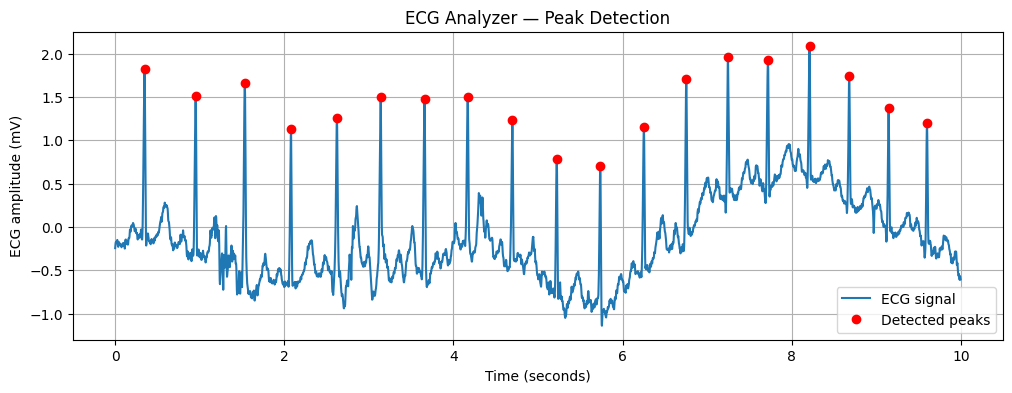

Number of detected peaks: 19


In [19]:
from scipy.signal import find_peaks

peaks, properties = find_peaks(
    ecg_segment,
    distance=int(0.25 * sampling_rate),
    prominence=0.5
)

plt.figure(figsize=(12, 4))
plt.plot(time, ecg_segment, label="ECG signal")
plt.plot(time[peaks], ecg_segment[peaks], "ro", label="Detected peaks")

plt.xlabel("Time (seconds)")
plt.ylabel("ECG amplitude (mV)")
plt.title("ECG Analyzer — Peak Detection")
plt.legend()
plt.grid(True)
plt.show()

print("Number of detected peaks:", len(peaks))

In [20]:
peak_times = time[peaks]

rr_intervals = np.diff(peak_times)

average_rr = np.mean(rr_intervals)

heart_rate = 60 / average_rr

print("Average interval:", round(average_rr, 3), "seconds")
print("Estimated heart rate:", round(heart_rate), "BPM")

Average interval: 0.514 seconds
Estimated heart rate: 117 BPM


In [21]:
print("ECG ANALYZER — REPORT")
print("---------------------")

print("Recording duration:",
      round(len(ecg_segment) / sampling_rate, 2), "seconds")

print("Sampling rate:", sampling_rate, "Hz")
print("Number of samples:", len(ecg_segment))
print("Detected peaks:", len(peaks))

print("Average R-R interval:",
      round(average_rr, 3), "seconds")

print("Estimated heart rate:",
      round(heart_rate), "BPM")

print("Minimum amplitude:",
      round(np.min(ecg_segment), 3), "mV")

print("Maximum amplitude:",
      round(np.max(ecg_segment), 3), "mV")

ECG ANALYZER — REPORT
---------------------
Recording duration: 10.0 seconds
Sampling rate: 360 Hz
Number of samples: 3600
Detected peaks: 19
Average R-R interval: 0.514 seconds
Estimated heart rate: 117 BPM
Minimum amplitude: -1.14 mV
Maximum amplitude: 2.09 mV



# ECG Analyzer

## Project Overview

ECG Analyzer is a beginner-level Python project for analyzing an electrocardiogram (ECG) signal. It visualizes the signal, detects candidate peaks, and estimates heart rate from the average interval between detected peaks.

## Features

- Loads a sample ECG recording.
- Visualizes the ECG signal over time.
- Calculates minimum, maximum, and average signal amplitude.
- Detects candidate peaks using a signal-processing function.
- Calculates average R-R intervals.
- Estimates heart rate in beats per minute (BPM).
- Generates a summary report.

## Technologies

- Python
- NumPy
- Matplotlib
- SciPy

## Example Results

- Recording duration: 10 seconds
- Sampling rate: 360 Hz
- Number of samples: 3,600
- Detected peaks: 19
- Average R-R interval: 0.514 seconds
- Estimated heart rate: 117 BPM

## Limitations

The peak-detection algorithm uses fixed parameters and may miss real peaks or detect false ones. Therefore, the estimated heart rate may be inaccurate.

This project is intended for educational purposes only. It is not a medical diagnostic tool.

## What I Learned

- Working with numerical arrays.
- Visualizing biomedical signals.
- Using Python scientific libraries.
- Detecting signal peaks.
- Calculating time intervals and heart rate.
- Understanding limitations of a simple signal-processing algorithm.
